# 04 - Do gap fills keep the chatter evidence?

Notebook 03 scored fills by their distance to the truth (MAE), where mean-fill won and diffusion only won on texture. That does not say whether a fill is *useful*. This notebook asks the original question instead: **if a patch has a gap, does filling it let a normal-vs-chatter classifier still tell the cut type?**

**Design**

| Step | Choice |
|---|---|
| Task | normal (0) vs chatter (2) per 0.36 s patch; the uncertain class (1) is dropped; labels are the stricter of the two operators (`max`) |
| Classifier | logistic regression (L2) on the per-frequency mean and temporal std of the dB spectrogram (256 numbers), trained on **clean** patches only |
| Held-out sessions | `Exp3-2` and `Exp4-3-2`, the only sessions that have both classes. Each is one fold: the classifier trains on every *other* session |
| Inputs at test time | the held-out patches with the same fixed gaps as notebook 03, filled by mean / linear / diffusion. Reference rows: `clean` (no gap) and `gap_left` (gap frames left at the floor) |
| Diffusion | one sample per patch, from a model trained **without** the held-out session (`train_diffusion.py --exclude-session`), so it never saw the patches it fills |
| Score | ROC AUC with a 95% bootstrap interval; then accuracy at the fixed 0.5 threshold, split into chatter recall and normal recall |

Code: `src/mtcut/chatter.py`, `scripts/eval_chatter_fills.py`.

## 1. Setup and load

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
try:
    import mtcut
except ImportError:  # package not installed (`pip install -e .`): use the source tree
    sys.path.insert(0, str(ROOT / "src"))
    import mtcut

from mtcut.chatter import bootstrap_auc, bootstrap_balanced_acc, recalls
from mtcut.config import PROCESSED_DIR
from mtcut.inpaint import LOW_BAND_BINS, load_patches, longest_span_ms
from mtcut.masking import BIN_HZ, FRAME_S, N_BINS, N_FRAMES

plt.rcParams.update({"figure.dpi": 100})
INPUTS = ["clean", "gap_left", "mean", "linear", "diffusion"]
FOLDS = ["Exp3-2", "Exp4-3-2"]
scores = pd.read_csv(PROCESSED_DIR / "chatter" / "scores.csv")
fills = {f: np.load(PROCESSED_DIR / "chatter" / f"fills_{f}.npz") for f in FOLDS}
clean_all, mask_all, meta = load_patches()
print(scores.groupby(["fold", "input"]).size().unstack("input")[INPUTS])

input     clean  gap_left  mean  linear  diffusion
fold                                              
Exp3-2      334       334   334     334        334
Exp4-3-2    305       305   305     305        305


## 2. Where the chatter labels are

Chatter patches exist almost only in three sessions, so the held-out folds are limited. `Exp4-3` is chatter only (nothing to separate), and the notebook 03 test sessions have no chatter at all. That is why this notebook does not reuse the earlier test split.

In [2]:
tab = meta.pivot_table(index=["split", "session"], columns="chatter_max", values="path_idx", aggfunc="size", fill_value=0)
tab.columns = ["normal (0)", "uncertain (1)", "chatter (2)"]
display(tab[(tab["chatter (2)"] > 0) | (tab["uncertain (1)"] > 0)])
print("sessions with only normal patches:", ", ".join(sorted(tab.index.get_level_values("session")[tab["chatter (2)"] + tab["uncertain (1)"] == 0])))

normal (0)  uncertain (1)  chatter (2)
split session                                         
test  Exp0-1            98              5            0
train Exp1-2             2              6            0
      Exp1-3             0              1            0
      Exp1-4            26              2            0
      Exp3-2            20            140          314
      Exp4-3             0              0          272
      Exp4-3-2          18             24          287
val   Exp0-3            45              3            0
      Exp1-1-2          35              0            1

sessions with only normal patches: Exp0-2, Exp1-1-A, Exp1-1-B, Exp1-5, Exp1-6, Exp1-7, Exp1-8, Exp1-9


## 3. What the classifier sees

Mean spectrum of the clean patches in the held-out session, normal against chatter. The classifier also uses the temporal std per bin, which is not drawn here.

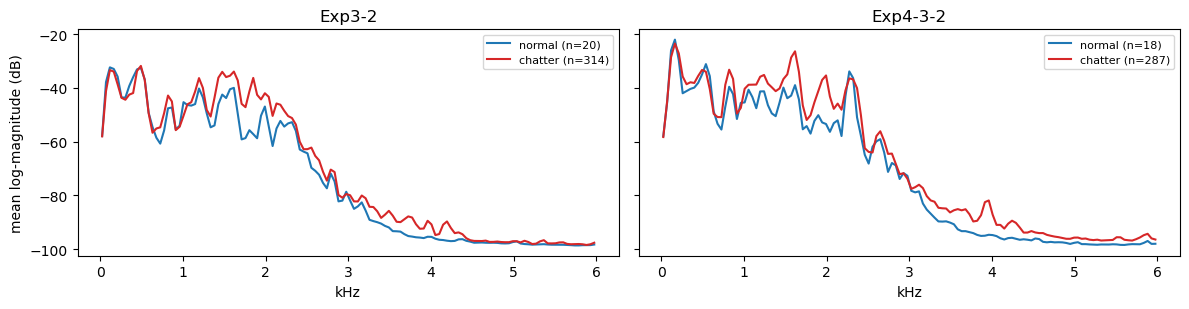

In [3]:
f_khz = (np.arange(N_BINS) + 0.5) * BIN_HZ / 1000
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for a, held in zip(ax, FOLDS):
    sel = (meta.session == held).to_numpy()
    for lab, name, col in [(0.0, "normal", "tab:blue"), (2.0, "chatter", "tab:red")]:
        s = sel & (meta.chatter_max == lab).to_numpy()
        a.plot(f_khz, clean_all[s].mean(axis=(0, 2)), color=col, label=f"{name} (n={s.sum()})")
    a.set_title(held); a.set_xlabel("kHz"); a.legend(fontsize=8)
ax[0].set_ylabel("mean log-magnitude (dB)")
plt.tight_layout(); plt.show()

## 4. Ranking quality: AUC

AUC: 1.0 means the classifier ranks every chatter patch above every normal one, 0.5 is chance. The interval is a bootstrap over patches (each class resampled separately), so it reflects the small number of normal patches (20 and 18 in the held-out sessions). `clean` is the ceiling: the same classifier on patches with no gap.

In [4]:
rows = []
for (fold, inp), g in scores.groupby(["fold", "input"]):
    y, s = g.y.to_numpy(), g.score.to_numpy()
    auc, lo, hi = bootstrap_auc(y, s)
    bacc, blo, bhi = bootstrap_balanced_acc(y, s)
    rec_c, rec_n = recalls(y, s)
    rows.append({"fold": fold, "input": inp, "auc": auc, "auc_lo": lo, "auc_hi": hi, "bal_acc": bacc, "bacc_lo": blo, "bacc_hi": bhi,
                 "chatter_recall": rec_c, "normal_recall": rec_n, "n_normal": int((y == 0).sum()), "n_chatter": int((y == 1).sum())})
res = pd.DataFrame(rows)
auc_tab = res.assign(auc_ci=lambda d: d.apply(lambda r: f"{r.auc:.3f} [{r.auc_lo:.3f}, {r.auc_hi:.3f}]", axis=1)).pivot(index="input", columns="fold", values="auc_ci").reindex(INPUTS)
display(auc_tab)

fold,Exp3-2,Exp4-3-2
input,,
clean,"0.999 [0.996, 1.000]","0.999 [0.997, 1.000]"
gap_left,"0.841 [0.789, 0.892]","0.678 [0.572, 0.780]"
mean,"1.000 [0.998, 1.000]","1.000 [1.000, 1.000]"
linear,"0.999 [0.996, 1.000]","1.000 [0.998, 1.000]"
diffusion,"0.998 [0.995, 1.000]","0.998 [0.994, 1.000]"


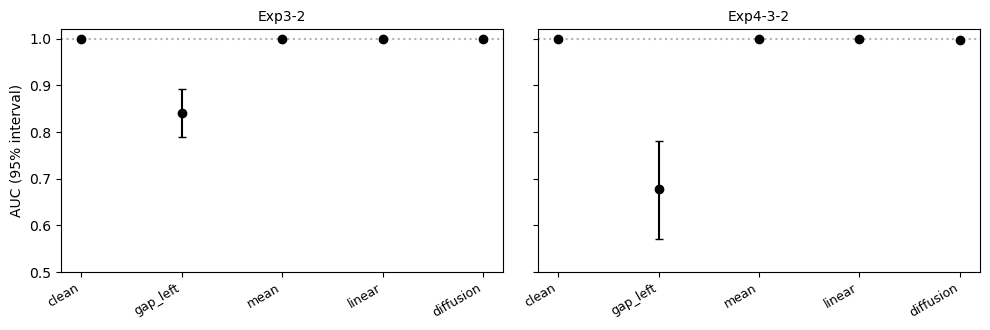

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for a, fold in zip(ax, FOLDS):
    r = res[res.fold == fold].set_index("input").loc[INPUTS]
    a.errorbar(range(len(INPUTS)), r.auc, yerr=[r.auc - r.auc_lo, r.auc_hi - r.auc], fmt="o", color="k", capsize=3)
    a.set_xticks(range(len(INPUTS))); a.set_xticklabels(INPUTS, rotation=30, ha="right", fontsize=9)
    a.set_title(fold, fontsize=10); a.set_ylim(0.5, 1.02); a.axhline(r.auc["clean"], color="0.7", ls=":")
ax[0].set_ylabel("AUC (95% interval)")
plt.tight_layout(); plt.show()

## 5. Decisions at a fixed threshold: accuracy

A deployed classifier uses one threshold (here 0.5, set by training on clean patches), so a fill that shifts the probabilities up or down changes the decisions even when the ranking stays the same. Balanced accuracy is the mean of **chatter recall** and **normal recall**. The interval only reflects which patches were drawn; it does not capture how much the probabilities shift with the input, and with 18-20 normal patches one patch moves normal recall by 5 points.

fold,Exp3-2,Exp4-3-2
input,,
clean,"0.978 [0.967, 0.989]","0.806 [0.694, 0.917]"
gap_left,"0.500 [0.500, 0.500]","0.500 [0.500, 0.500]"
mean,"0.906 [0.884, 0.927]","0.889 [0.778, 0.972]"
linear,"0.954 [0.936, 0.970]","0.917 [0.833, 1.000]"
diffusion,"0.992 [0.984, 0.998]","0.778 [0.667, 0.889]"


chatter_recall          normal_recall         
fold              Exp3-2 Exp4-3-2        Exp3-2 Exp4-3-2
input                                                   
clean              0.955      1.0           1.0    0.611
gap_left           1.000      1.0           0.0    0.000
mean               0.812      1.0           1.0    0.778
linear             0.908      1.0           1.0    0.833
diffusion          0.984      1.0           1.0    0.556

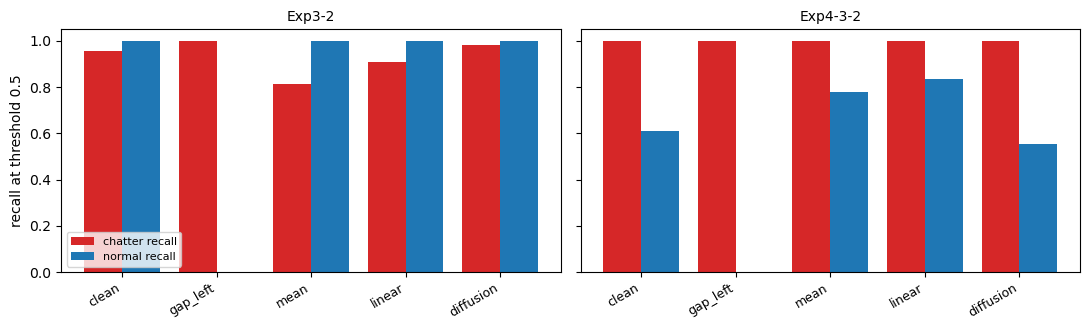

In [6]:
acc_tab = res.assign(bal_acc_ci=lambda d: d.apply(lambda r: f"{r.bal_acc:.3f} [{r.bacc_lo:.3f}, {r.bacc_hi:.3f}]", axis=1))
display(acc_tab.pivot(index="input", columns="fold", values="bal_acc_ci").reindex(INPUTS))
display(res.pivot(index="input", columns="fold", values=["chatter_recall", "normal_recall"]).reindex(INPUTS).round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for a, fold in zip(ax, FOLDS):
    r = res[res.fold == fold].set_index("input").loc[INPUTS]
    x = np.arange(len(INPUTS))
    a.bar(x - 0.2, r.chatter_recall, 0.4, label="chatter recall", color="tab:red")
    a.bar(x + 0.2, r.normal_recall, 0.4, label="normal recall", color="tab:blue")
    a.set_xticks(x); a.set_xticklabels(INPUTS, rotation=30, ha="right", fontsize=9); a.set_title(fold, fontsize=10); a.set_ylim(0, 1.05)
ax[0].set_ylabel("recall at threshold 0.5"); ax[0].legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

## 6. Examples

One chatter and one normal patch per held-out session (the longest gaps among the patches): the clean patch, the gap left empty, and each fill, with the classifier's chatter probability in the corner. The images show 0-3 kHz.

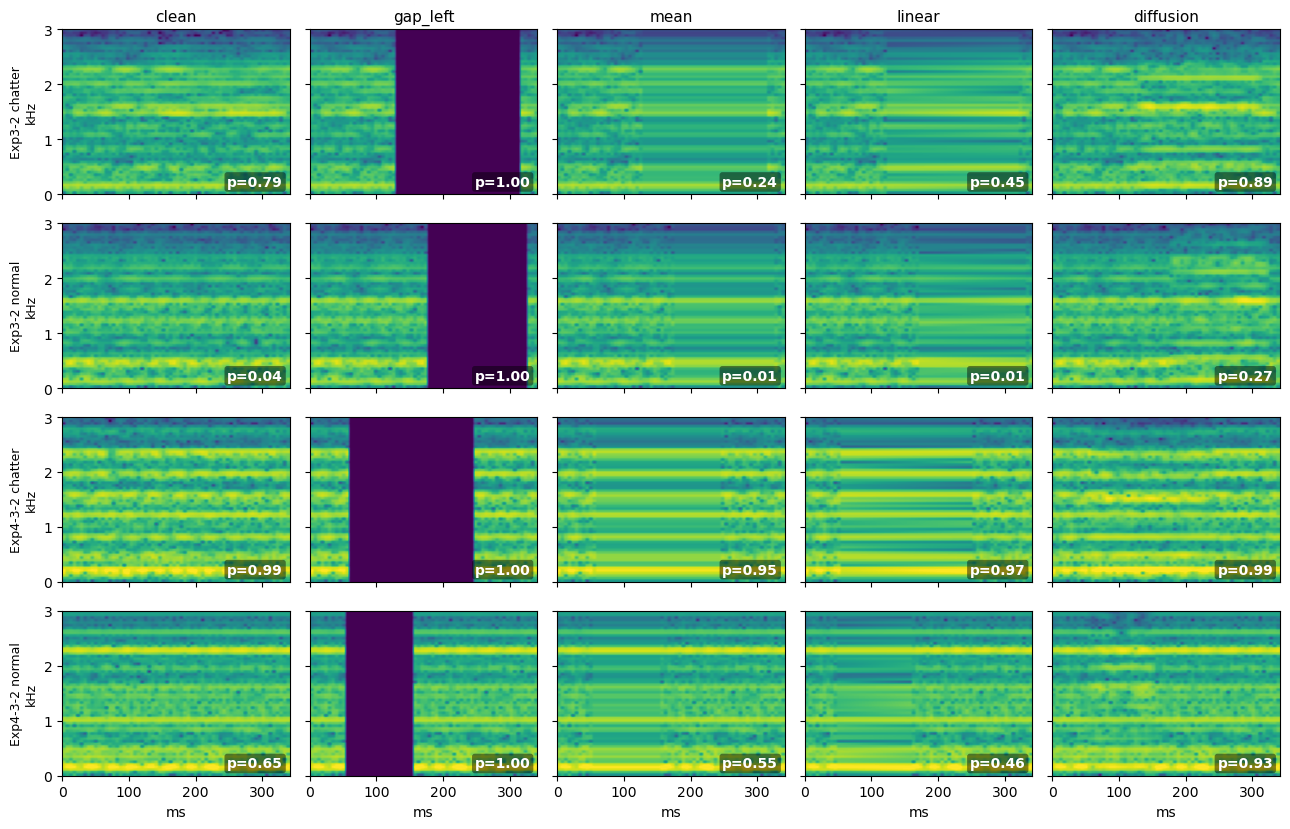

In [7]:
cols = ["clean", "gap_left", "mean", "linear", "diffusion"]
prob = scores.set_index(["fold", "input", "patch_idx"]).score

fig, ax = plt.subplots(4, len(cols), figsize=(2.6 * len(cols), 8.4), sharex=True, sharey=True)
r = 0
for fold in FOLDS:
    fz = fills[fold]
    span = longest_span_ms(fz["mask"])
    for lab, name in [(1, "chatter"), (0, "normal")]:
        cand = np.flatnonzero(fz["y"] == lab)
        k = cand[np.argsort(-span[cand])[: max(3, len(cand) // 10)]][0]
        pid = int(fz["patch_idx"][k])
        for c, key in enumerate(cols):
            a = ax[r, c]
            a.imshow(fz[key][k].astype(np.float32)[:LOW_BAND_BINS], origin="lower", aspect="auto", vmin=-100, vmax=-20,
                     extent=[0, N_FRAMES * FRAME_S * 1000, 0, LOW_BAND_BINS * BIN_HZ / 1000])
            a.text(0.97, 0.05, f"p={prob[(fold, key, pid)]:.2f}", transform=a.transAxes, ha="right", color="white", fontsize=10,
                   weight="bold", bbox=dict(boxstyle="round,pad=0.2", fc="black", alpha=0.45, lw=0))
            if r == 0: a.set_title(key, fontsize=11)
            if c == 0: a.set_ylabel(f"{fold} {name}\nkHz", fontsize=9)
        r += 1
for a in ax[-1]: a.set_xlabel("ms")
plt.tight_layout(); plt.show()

## 7. Takeaways

**Result: every reasonable fill keeps the clean patches' ranking quality (AUC). At a fixed threshold the fills shift the decisions in different directions, and neither direction is better overall.**

| | clean | gap_left | mean | linear | diffusion |
|---|---|---|---|---|---|
| AUC, `Exp3-2` | 0.999 | 0.841 | 1.000 | 0.999 | 0.998 |
| AUC, `Exp4-3-2` | 0.999 | 0.678 | 1.000 | 1.000 | 0.998 |
| Balanced accuracy, `Exp3-2` | 0.978 | 0.500 | 0.906 | 0.954 | 0.992 |
| Balanced accuracy, `Exp4-3-2` | 0.806 | 0.500 | 0.889 | 0.917 | 0.778 |

* **AUC: no difference between the fills.** Mean, linear and diffusion are all within 0.002 of the clean patches. Only leaving the gap empty hurts (0.68 to 0.84).
* **Accuracy is not a win for diffusion.** Diffusion is the best on `Exp3-2` (0.992) and the worst on `Exp4-3-2` (0.778, against 0.889 for mean-fill and 0.917 for linear). It also beats the clean patches on `Exp3-2` (0.992 against 0.978), and a fill cannot hold more information than the real data. That points to a threshold effect, not a better fill.
* **What the fills do is shift the operating point.** Mean-fill and linear flatten the gap, which lowers the std features, so they call fewer patches chatter: chatter recall falls to 0.81 (mean) and 0.91 (linear) on `Exp3-2`. Diffusion adds texture, which raises them: chatter recall 0.98 on `Exp3-2`, but normal recall only 0.56 on `Exp4-3-2` (more false alarms). Whether that helps depends on which error the clean classifier already makes. On `Exp4-3-2` the clean classifier already calls too many normal patches chatter (normal recall 0.61), so a fill that pushes toward "normal" looks better there.
* **Leaving the gap empty** puts floor-valued frames into the features, which inflates the std and makes every patch look like chatter (chatter recall 1.00, normal recall 0.00). It is a weak reference, so the fair no-effort baseline is mean-fill, which keeps the observed per-frequency mean unchanged.
* **Single patches with long gaps can move a lot, in both directions.** In the examples (chosen for their long gaps), mean-fill drops a chatter patch from p=0.79 to 0.24, and diffusion raises a normal `Exp4-3-2` patch from 0.65 to 0.93.

**Caveats**
* **Ceiling effect:** clean AUC is already 0.999, so there is no room for a better fill to show a gain in ranking. This test is easy, and the features are averages, which cannot see the realistic texture that is diffusion's strength.
* **Small test:** two folds, with 20 and 18 normal patches in the held-out sessions, so one patch moves normal recall by 5 points. The accuracy intervals reflect only which patches were drawn, not the threshold shift. Chatter is tied to the session (tool, material, gain), so a classifier may partly learn the setup.
* **Classifier choice:** I first ran logistic regression and gradient boosting, then kept logistic regression because it is simpler and had the higher clean AUC (0.999 against 0.955 for gradient boosting on `Exp4-3-2`). The AUC conclusion was the same with both.
* **Selection:** the loudest chatter cuts are excluded (they clip on sensor 2), and the uncertain class (1) is dropped, using the stricter-of-two-operators (`max`) label.
* **One draw per patch:** one fixed mask and one diffusion sample per patch, from a small model trained for 22 minutes (about 5.9k steps).

**Not tested (where fills might separate)**
* Heavier masks (60-80% of frames missing) or longer gaps.
* A classifier that uses temporal structure (a small CNN) and so can see texture.
* Using the filled patches as training data for the classifier (augmentation), instead of only at test time.